# 6 · Redundancy and null space

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rudip1/learn-manipulator-control/blob/main/2_notebooks/exercises/06_redundancy.ipynb)

Theory: [`1_theory/06_redundancy.md`](../../1_theory/06_redundancy.md) · notation:
[`00_notation.md`](../../1_theory/00_notation.md)

In [1]:
# Install the module when it is not importable yet (Colab, fresh environment).
import importlib.util
if importlib.util.find_spec("manipulator_control") is None:
    %pip install -q git+https://github.com/Rudip1/learn-manipulator-control

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import manipulator_control as mc
from manipulator_control import plotting

plt.rcParams.update({"figure.dpi": 80, "axes.grid": True})
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(6)

## Recap

- With $n > m$ joints the task velocity $v$ is produced by $\dot q = J^\dagger v + (I - J^\dagger J)z$ for any $z$
  (eq. 6.1); $r = n - m$ is the degree of redundancy.
- $N = I - J^\dagger J$ is the orthogonal projector onto the null space: $N = N^T = N^2$, $JN = 0$ (eq. 6.3).
  Motion $\dot q = Nz$ is self-motion: the joints move, the end-effector does not.
- The weighted pseudoinverse $J_W^\dagger = W^{-1}J^T(JW^{-1}J^T)^{-1}$ minimises $\dot q^TW\dot q$ (eq. 6.6).
- Gradient projection: $z = -k_0\nabla H$ lowers $H$ by $k_0\|N\nabla H\|^2$ without touching the task (eqs.
  6.7–6.8). Joint centering (6.9) and manipulability (6.11) are the classic objectives.
- With the DLS inverse, $I - J_\lambda^\dagger J$ leaks into the task by up to $\lambda/2$ (eq. 6.12).

## The null space of a three-link arm

The planar arm with $l = (0.5, 0.4, 0.3)$ m controlling its tip position has $n = 3$, $m = 2$: one degree of
redundancy, so $N$ has rank 1.

In [3]:
arm = mc.robots.planar([0.5, 0.4, 0.3])
q = np.array([0.2, 0.9, -0.6])
J = mc.geometric_jacobian(arm, q)[:2]
N = mc.null_space_projector(J)
print("N =\n", N)
print("trace N =", np.trace(N), "  |J N| =", np.abs(J @ N).max(), "  |N N - N| =", np.abs(N @ N - N).max())

N =
 [[ 0.1008 -0.0349 -0.2991]
 [-0.0349  0.0121  0.1034]
 [-0.2991  0.1034  0.8871]]
trace N = 0.9999999999999992   |J N| = 4.528937043932625e-16   |N N - N| = 1.4155343563970746e-15


Walk along the null space at unit speed, using the previous direction as $z$ so the walk does not stall, and
watch the tip: it stays (almost) put while the joints go through a full loop. The small drift is the error of the
Euler step; a controller removes it with the task feedback.

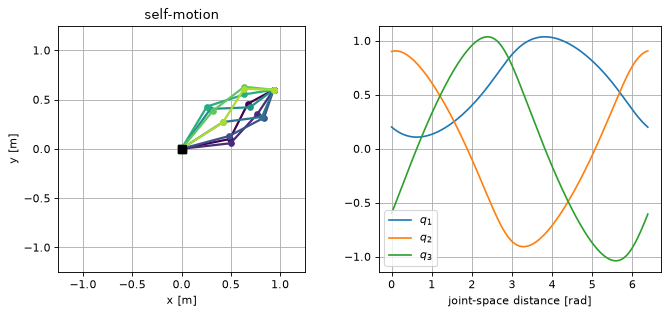

loop closed after 6.4 rad; tip drift 1.11 mm


In [4]:
d, h = np.array([0.0, 0.0, 1.0]), 2e-3
path = [q.copy()]
p_start = arm.end_effector(q)[:2, 3]
for k in range(20000):
    J = mc.geometric_jacobian(arm, q)[:2]
    d = mc.null_space_projector(J) @ d
    d /= np.linalg.norm(d)
    q = q + h * d
    path.append(q.copy())
    if k > 500 and np.linalg.norm(q - path[0]) < 1e-2:
        break
path = np.array(path)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i in np.linspace(0, len(path) - 1, 9).astype(int)[:-1]:
    plotting.draw_planar_arm(ax[0], arm.frames(path[i]), color=plt.cm.viridis(i / len(path)), linewidth=2)
plotting.planar_axes(ax[0], limit=1.25, title="self-motion")
ax[1].plot(np.arange(len(path)) * h, path)
ax[1].set_xlabel("joint-space distance [rad]"); ax[1].legend(["$q_1$", "$q_2$", "$q_3$"])
plt.show()
print(f"loop closed after {len(path) * h:.1f} rad; tip drift {np.linalg.norm(arm.end_effector(q)[:2, 3] - p_start) * 1e3:.2f} mm")

## Choosing which joints move: the weighted pseudoinverse

Ask for the same tip velocity three times: with $W = I$, with joint 1 a hundred times more expensive, and with
joint 3 a hundred times more expensive. Every solution produces exactly $v$; they differ in who does the work.

In [5]:
q = np.array([0.2, 0.9, -0.6])
J = mc.geometric_jacobian(arm, q)[:2]
v = np.array([0.1, -0.05])
for name, W in [("W = I", np.eye(3)), ("joint 1 heavy", np.diag([100.0, 1, 1])), ("joint 3 heavy", np.diag([1, 1, 100.0]))]:
    qdot = mc.weighted_pseudoinverse(J, W) @ v
    print(f"{name:14s} qdot = {qdot}   J qdot - v = {J @ qdot - v}")

W = I          qdot = [ 0.076  -0.3087  0.0616]   J qdot - v = [ 0. -0.]
joint 1 heavy  qdot = [ 0.0069 -0.2848  0.2666]   J qdot - v = [-0.  0.]
joint 3 heavy  qdot = [ 0.0966 -0.3158  0.0007]   J qdot - v = [-0.  0.]


## Gradient projection: joint centering

The worked example of section 6.4: start far from the middle of the joint ranges and reach $(0.6, 0.5)$ m with and
without the joint-centering objective. The whole loop runs in C++ (`simulate_redundancy`).

k0 =    0: final error 2.4e-10 m,  H = 0.0977,  max|q3| = 1.86 rad
k0 =    5: final error 5.6e-06 m,  H = 0.0888,  max|q3| = 2.24 rad
k0 =   20: final error 5.5e-06 m,  H = 0.0272,  max|q3| = 2.36 rad


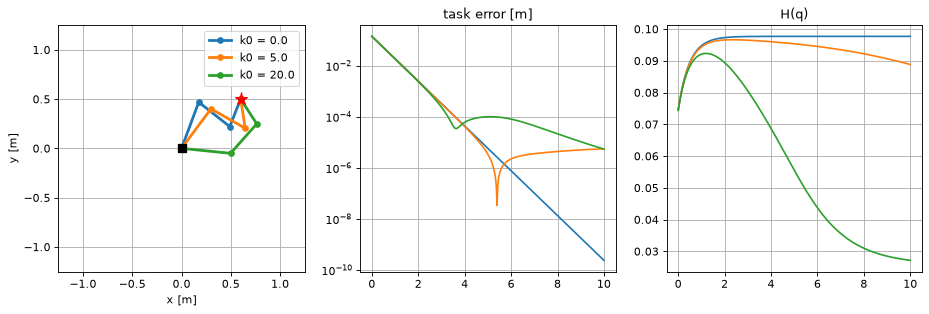

In [6]:
q_min, q_max = np.array([-np.pi / 2, -2.0, -2.0]), np.array([np.pi / 2, 2.0, 2.0])
q0 = np.array([1.2, -1.5, 1.6])
T_d = np.eye(4); T_d[:2, 3] = [0.6, 0.5]
cfg = mc.ResolvedRateConfig(space=mc.TaskSpace.PlanarPosition, gain=2.0, dt=0.01, steps=1000)
runs = {k0: mc.simulate_redundancy(arm, q0, T_d, cfg, mc.RedundancyConfig(mc.SecondaryObjective.JointCentering, k0, q_min, q_max))
        for k0 in [0.0, 5.0, 20.0]}
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for k, (k0, r) in enumerate(runs.items()):
    plotting.draw_planar_arm(ax[0], arm.frames(r.trajectory.q[-1]), color=f"C{k}", label=f"k0 = {k0}")
    ax[1].semilogy(r.trajectory.t, r.trajectory.error_norm + 1e-12, color=f"C{k}")
    ax[2].plot(r.trajectory.t, r.objective, color=f"C{k}")
    print(f"k0 = {k0:4.0f}: final error {r.trajectory.error_norm[-1]:.1e} m,  H = {r.objective[-1]:.4f},  max|q3| = {np.abs(r.trajectory.q[:, 2]).max():.2f} rad")
ax[0].plot(*T_d[:2, 3], "r*", markersize=12); plotting.planar_axes(ax[0], limit=1.25); ax[0].legend()
ax[1].set_title("task error [m]"); ax[2].set_title("H(q)")
plt.show()

Look at `max|q3|`: without the objective joint 3 stays inside its limit of 2 rad, with joint centering it goes
*past* it. $H$ is a sum over the joints (eq. 6.9); lowering the sum can push one joint further out, and nothing in
eq. (6.8) stops it. Joint centering *prefers* the middle, it does not enforce the limits. That needs priorities
(chapters 7–8).

## Gradient projection: manipulability

The four-link arm of section 6.4 starts zig-zagged. Maximising $w$ in the null space straightens it into a
better-conditioned configuration at the same tip position.

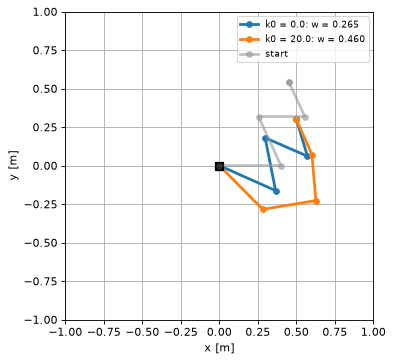

In [7]:
arm4 = mc.robots.planar([0.4, 0.35, 0.3, 0.25])
q0_4 = np.array([0.0, 2.0, -2.0, 2.0])
T4 = np.eye(4); T4[:2, 3] = [0.5, 0.3]
fig, ax = plt.subplots(figsize=(5, 5))
for k, k0 in enumerate([0.0, 20.0]):
    r = mc.simulate_redundancy(arm4, q0_4, T4, cfg, mc.RedundancyConfig(mc.SecondaryObjective.Manipulability, k0))
    plotting.draw_planar_arm(ax, arm4.frames(r.trajectory.q[-1]), color=f"C{k}", label=f"k0 = {k0}: w = {r.objective[-1]:.3f}")
plotting.draw_planar_arm(ax, arm4.frames(q0_4), color="0.6", alpha=0.6, label="start")
plotting.planar_axes(ax, limit=1.0); ax.legend(fontsize=8); plt.show()

## ✏️ Exercises

### ✏️ 1. The projector from a null-space basis

Compute a basis $Z$ of $\mathcal{N}(J)$ from the SVD (the right singular vectors with zero singular value) and
build $N = Z(Z^TZ)^{-1}Z^T$ (eq. 6.4). Do not use a pseudoinverse.

In [8]:
def projector_from_basis(J, tol=1e-10):
    ### BEGIN SOLUTION
    U, s, Vt = np.linalg.svd(J)
    rank = int(np.sum(s > tol * s[0]))
    Z = Vt[rank:].T
    return Z @ np.linalg.inv(Z.T @ Z) @ Z.T
    ### END SOLUTION

In [9]:
for _ in range(10):
    J = rng.normal(size=(3, 6))
    if rng.uniform() < 0.5:
        J[2] = J[0] - 2 * J[1]          # rank deficient
    assert np.allclose(projector_from_basis(J), mc.null_space_projector(J), atol=1e-9)
print("✓ projector_from_basis")

✓ projector_from_basis


### ✏️ 2. The null space of a planar three-link arm in one line

For a $2\times3$ Jacobian with rows $a^T$ and $b^T$, the null space is spanned by $a \times b$. Why? Use this to
write $N$ without any decomposition.

<!-- BEGIN SOLUTION -->
$a\times b$ is orthogonal to both $a$ and $b$, so $J(a\times b) = (a^T(a\times b), b^T(a\times b)) = 0$; it is
non-zero when the rows are independent, and the null space is one-dimensional, so it spans it. Then
$N = nn^T/\|n\|^2$ with $n = a\times b$.
<!-- END SOLUTION -->

In [10]:
def projector_3r(J):
    ### BEGIN SOLUTION
    n = np.cross(J[0], J[1])
    return np.outer(n, n) / (n @ n)
    ### END SOLUTION

In [11]:
for _ in range(20):
    q = rng.uniform(-np.pi, np.pi, 3)
    J = mc.geometric_jacobian(arm, q)[:2]
    assert np.allclose(projector_3r(J), mc.null_space_projector(J), atol=1e-9)
print("✓ projector_3r")

✓ projector_3r


### ✏️ 3. Joint-centering gradient

Implement eq. (6.10).

In [12]:
def grad_H(q, q_min, q_max):
    ### BEGIN SOLUTION
    return (q - 0.5 * (q_min + q_max)) / (q_max - q_min) ** 2 / q.size
    ### END SOLUTION

In [13]:
for _ in range(20):
    q = rng.uniform(q_min, q_max)
    assert np.allclose(grad_H(q, q_min, q_max), mc.joint_centering_gradient(q, q_min, q_max))
print("✓ grad_H")

✓ grad_H


### ✏️ 4. Weighted minimum norm by the KKT system

Solve eq. (6.5) as one linear system and return $\dot q$. Compare with `mc.weighted_pseudoinverse`.

In [14]:
def weighted_min_norm(J, W, v):
    ### BEGIN SOLUTION
    m, n = J.shape
    K = np.block([[W, J.T], [J, np.zeros((m, m))]])
    return np.linalg.solve(K, np.concatenate([np.zeros(n), v]))[:n]
    ### END SOLUTION

In [15]:
for _ in range(10):
    J = rng.normal(size=(2, 4)); A = rng.normal(size=(4, 4)); W = A @ A.T + np.eye(4); v = rng.normal(size=2)
    assert np.allclose(weighted_min_norm(J, W, v), mc.weighted_pseudoinverse(J, W) @ v)
print("✓ weighted_min_norm")

✓ weighted_min_norm


## 🔨 Break it

### 🔨 1. Forget the projector

Add $z = -k_0\nabla H$ directly to the minimum-norm solution. $H$ drops even further — but the task feedback now
fights the secondary motion and the tip never reaches the target.

In [16]:
for project in [True, False]:
    r = mc.simulate_redundancy(arm, q0, T_d, cfg, mc.RedundancyConfig(mc.SecondaryObjective.JointCentering, 20.0, q_min, q_max, project=project))
    print(f"project = {project!s:5s}: final error {r.trajectory.error_norm[-1]:.2e} m,  H = {r.objective[-1]:.4f}")

project = True : final error 5.52e-06 m,  H = 0.0272
project = False: final error 1.38e-01 m,  H = 0.0208


### 🔨 2. Damped least squares in the null-space term

Use $I - J_\lambda^\dagger J$ as the "projector". It leaks into the task by up to $\lambda/2$ (eq. 6.12), worst
where a singular value equals $\lambda$. Sweep $q_2$ through the stretched configuration.

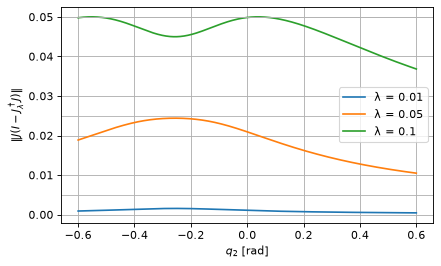

In [17]:
q2s = np.linspace(-0.6, 0.6, 601)
plt.figure(figsize=(6, 3.5))
for lam in [0.01, 0.05, 0.1]:
    leak = [np.linalg.norm(mc.geometric_jacobian(arm, np.array([0.3, x, 0.4]))[:2]
                           @ mc.null_space_projector_of(mc.geometric_jacobian(arm, np.array([0.3, x, 0.4]))[:2],
                                                        mc.dls_inverse(mc.geometric_jacobian(arm, np.array([0.3, x, 0.4]))[:2], lam)), 2)
            for x in q2s]
    plt.plot(q2s, leak, label=f"λ = {lam}"); plt.axhline(lam / 2, color="0.7", linewidth=0.8)
plt.xlabel("$q_2$ [rad]"); plt.ylabel(r"$\|J(I - J_\lambda^\dagger J)\|$"); plt.legend(); plt.show()

### 🔨 3. A null-space gain that is too high

The null-space term is integrated with the same $\Delta t$ as the task. Raise $k_0$ until the self-motion
overshoots and diverges — the same discrete-time instability as a task gain that is too high (chapter 4).

In [18]:
for k0 in [20, 2000, 8000, 10000]:
    with np.errstate(all="ignore"):
        r = mc.simulate_redundancy(arm, q0, T_d, cfg, mc.RedundancyConfig(mc.SecondaryObjective.JointCentering, k0, q_min, q_max))
    print(f"k0 = {k0:6d}: final H = {r.objective[-1]:.3g},  final error = {r.trajectory.error_norm[-1]:.2g} m")

k0 =     20: final H = 0.0272,  final error = 5.5e-06 m
k0 =   2000: final H = 0.0257,  final error = 9.9e-11 m
k0 =   8000: final H = 0.0257,  final error = 1.1e-09 m
k0 =  10000: final H = 2.22e+94,  final error = 1.4 m


### 🔨 4. No redundancy, no null space

The two-link arm controlling its tip position has $n = m = 2$. Away from singularities its null space is empty:
$N = 0$ and no secondary objective can do anything. At a singularity a direction appears — the one that cannot
move the tip.

In [19]:
arm2 = mc.robots.planar([0.75, 0.5])
for q2 in [1.0, 0.0]:
    J2 = mc.geometric_jacobian(arm2, np.array([0.4, q2]))[:2]
    print(f"q2 = {q2}: N =\n{mc.null_space_projector(J2)}")

q2 = 1.0: N =
[[ 0. -0.]
 [ 0.  0.]]
q2 = 0.0: N =
[[ 0.1379 -0.3448]
 [-0.3448  0.8621]]


## What to remember

- Redundancy belongs to the arm *and* the task: $r = n - m$.
- $N = I - J^\dagger J$ is symmetric, idempotent and kills the task; $\dot q = Nz$ moves the joints, not the
  end-effector.
- $W$ chooses which joints do the work; $W = I$ is the pseudoinverse.
- Gradient projection optimises a secondary criterion without disturbing the task — it prefers, it does not
  enforce. Hard limits need priorities (chapters 7–8).
- With DLS the null-space term leaks into the task by up to $\lambda/2$.